# 06: Does the Answer Survive Different Choices?

**The question here: would a different analyst, making different but equally reasonable decisions, get a different answer?**

Everything so far rests on judgement calls:

- use only **Q1**, the first of qualifying's three segments, because it is the one part every driver runs;
- drop any driver-session whose best lap is more than 7% slower than the session's fastest, which is F1's own **107% rule**;
- keep wet sessions rather than treating rain as bad data;
- treat each team in each season as a separate car, so the 2023 Red Bull and the 2024 Red Bull count as two different machines.

Each was argued for at the time. But an answer that only holds under one exact set of choices is not much of an answer, so this notebook refits under different ones and checks whether the numbers move.

**One thing to know before the tables start.** The model is fitted on the **square root** of the percentage gap to the session's fastest lap. The raw gap is heavily skewed by a handful of ruined laps, and the square root pulls that tail in. Every "spread" figure below is a standard deviation on that square-root scale. That is why the headline reads 1.69 here and 2.8 in notebook 03: 2.8 is a ratio of variances, and squaring converts between them.

**One test was written down before it was run.** Notebook 03 turned up something that looked wrong: the 2023 Red Bull, which won 21 of that season's 22 races, came out only 12th of the 81 cars in the data. The explanation offered there was **sandbagging**: a team deliberately lapping below its true pace. To survive Q1 a driver only has to avoid being one of the five slowest, so Verstappen never needed his best lap there, only a comfortable one. The teams at the front can hold back; the teams at the back cannot. That squashes the measured gap *between* teams while leaving the comparison *within* a team largely intact, since both cars in a garage are usually managed together.

That explanation makes a prediction that can fail. **Refit the model on Q2 or Q3, where the front runners push, and the gaps between cars should get bigger, while the gaps between drivers should stay where they are.**

**Contents:**
1. Rebuilding the data with every segment.
2. The test written in advance: Q1 versus Q2 and Q3.
3. The same test with the field held constant.
4. Four ways this could still be wrong.
5. Sandbagging, or just a faster track?
6. The ranking holds; the exact ratio doesn't.
7. What this means for the headline number.
8. Quantified takeaways.

## Rebuilding the data with every segment

**The lap times have to be downloaded again: notebook 01 kept only the Q1 rows.** Q1 was the settled choice for the main model, so the Q2 and Q3 laps were discarded. Testing the sandbagging prediction needs them back.

So the laps are fetched again from the same public archive notebook 01 used, keeping all three segments. Nothing else about the processing changes.

This takes a few minutes to run.

In [11]:
!pip install -q bambi arviz

import glob
from urllib.parse import quote

import numpy as np
import pandas as pd
import requests
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pd.set_option('display.max_columns', None)

FIT_ARGS = dict(draws=1500, tune=1000, chains=4, random_seed=0, target_accept=0.99)

In [12]:
def load_session_json(year, grand_prix, session, filename):
    url = (f'https://raw.githubusercontent.com/TracingInsights/{year}/main/'
           f'{quote(grand_prix)}/{quote(session)}/{filename}')
    return requests.get(url, timeout=30).json()


def grand_prix_names(year):
    url = f'https://api.github.com/repos/TracingInsights/{year}/contents'
    return [entry['name'] for entry in requests.get(url, timeout=30).json()
            if entry['type'] == 'dir' and 'Grand Prix' in entry['name']]


frames = []
for year in range(2018, 2026):
    names = grand_prix_names(year)
    print(f'{year}: {len(names)} GPs', end=' ')
    for grand_prix in names:
        try:
            payload = load_session_json(year, grand_prix, 'Qualifying', 'session_laptimes.json')
        except Exception:
            continue
        frame = pd.DataFrame(payload)
        frame['season'] = year
        frame['gp'] = grand_prix
        frames.append(frame)
    print('done')

all_laps = pd.concat(frames, ignore_index=True)
all_laps['time'] = pd.to_numeric(all_laps['time'], errors='coerce')
print()
print('laps:', len(all_laps))

2018: 21 GPs done
2019: 21 GPs done
2020: 17 GPs done
2021: 22 GPs done
2022: 22 GPs done
2023: 22 GPs done
2024: 24 GPs done
2025: 24 GPs done

laps: 53690


In [13]:
def build_pace_table(laps, segment):
    """Driver-session pace for one qualifying segment, as a % gap to that segment's fastest lap."""
    valid = laps[laps['iacc'].eq(True) & laps['del'].eq(False) & laps['qs'].eq(segment)]

    table = (valid.groupby(['season', 'gp', 'team', 'drv'])['time']
             .agg(best_lap='min', n_valid_laps='size')
             .reset_index())

    fastest = table.groupby(['season', 'gp'])['best_lap'].transform('min')
    table['gap_to_fastest'] = (table['best_lap'] - fastest) / fastest * 100
    table['team_season'] = table['team'] + ' ' + table['season'].astype(str)
    table['sqrt_gap'] = np.sqrt(table['gap_to_fastest'])

    rain = laps.groupby(['season', 'gp'])['wR'].apply(lambda s: s.eq(True).mean())
    table = table.join(rain.rename('rain_fraction'), on=['season', 'gp'])
    table['within_107'] = table['gap_to_fastest'] <= 7
    return table


segments = {name: build_pace_table(all_laps, name) for name in ['Q1', 'Q2', 'Q3']}

summary = pd.DataFrame({
    name: {
        'rows': len(table),
        'drivers': table['drv'].nunique(),
        'team_seasons': table['team_season'].nunique(),
        'sessions': table.groupby(['season', 'gp']).ngroups,
    }
    for name, table in segments.items()
}).T
print(summary)

    rows  drivers  team_seasons  sessions
Q1  3029       43            81       156
Q2  2328       39            80       158
Q3  1555       34            77       159


## The test written in advance: Q1 versus Q2 and Q3

Qualifying runs in three parts, and each one keeps fewer cars:

| segment | rows | drivers | who's in it |
|---|---|---|---|
| Q1 | 3,029 | 43 | everyone |
| Q2 | 2,328 | 39 | slowest five eliminated |
| Q3 | 1,555 | 34 | only the fastest ten |

Stated in notebook 03 before this was run: **the gaps between cars should get bigger, and the gaps between drivers should stay about where they are.** The teammate comparison was never much distorted to begin with. Neither half carries a numeric threshold. That is a weakness of the prediction, and it shows up later when one half lands in between.

**Neither Q2 nor Q3 is a fair swap for Q1.** Q3 has the freshest softs and a rubbered-in track, and until September 2020 it also had qualifying engine modes. But it holds only the fastest ten cars, and measuring how far apart cars are using only the best of them should make them look *more alike*, not less.

**Q2 is worse.** From 2014 to 2021, four of the eight seasons here, drivers who reached Q3 had to start the race on their Q2 tyre, so front runners deliberately ran Q2 on a harder, slower compound. Q2 is not a cleaner segment than Q1, it is a differently distorted one, distorted for exactly the teams under test. The rule was dropped for 2022.

**One wrinkle about the 107% rule.** It applies to Q1 alone in the regulations, and stewards usually let a driver outside it start anyway. Applying the same cut to Q2 and Q3 borrows the rule rather than following it, done so the fits differ by segment and nothing else. It still bites: 14 rows in Q2 and 7 in Q3, against 21 in Q1.

In [14]:
FORMULA = 'sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)'

PRIORS = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    'sigma': bmb.Prior('HalfNormal', sigma=0.5),
}


def fit_variant(data, label):
    model = bmb.Model(FORMULA, data=data, priors=PRIORS)
    fitted = model.fit(**FIT_ARGS)
    diagnostics = az.summary(fitted)
    print(f'{label:24s} rows={len(data):5d}  '
          f'divergences={int(fitted.sample_stats["diverging"].sum()):3d}  '
          f'max R-hat={diagnostics["r_hat"].max():.4f}')
    return fitted


fits = {}
for name, table in segments.items():
    fits[name] = fit_variant(table[table['within_107']], f'{name} (107% applied)')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 139 seconds.


Q1 (107% applied)        rows= 3008  divergences=  0  max R-hat=1.0043


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


...

Q2 (107% applied)        rows= 2314  divergences=  0  max R-hat=1.0035


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 90 seconds.


Q3 (107% applied)        rows= 1548  divergences=  0  max R-hat=1.0059


In [15]:
def effect_sizes(fitted):
    posterior = fitted.posterior
    driver = posterior['1|drv_sigma'].values.flatten()
    car = posterior['1|team_season_sigma'].values.flatten()
    return {
        'driver_sd': np.median(driver),
        'car_sd': np.median(car),
        'residual_sd': np.median(posterior['sigma'].values.flatten()),
        'car_over_driver': np.median(car / driver),
        'ratio_lower': np.percentile(car / driver, 5.5),
        'ratio_upper': np.percentile(car / driver, 94.5),
    }


comparison = pd.DataFrame({name: effect_sizes(fitted) for name, fitted in fits.items()}).T
print(comparison.round(3))

    driver_sd  car_sd  residual_sd  car_over_driver  ratio_lower  ratio_upper
Q1      0.136   0.229        0.296            1.687        1.245        2.285
Q2      0.114   0.247        0.294            2.175        1.545        3.037
Q3      0.146   0.273        0.317            1.868        1.317        2.693


In [16]:
def sd_interval(fitted, parameter):
    draws = fitted.posterior[parameter].values.flatten()
    return np.percentile(draws, [5.5, 50, 94.5])


intervals = pd.DataFrame({
    name: {
        'driver_lo': sd_interval(fitted, '1|drv_sigma')[0],
        'driver_med': sd_interval(fitted, '1|drv_sigma')[1],
        'driver_hi': sd_interval(fitted, '1|drv_sigma')[2],
        'car_lo': sd_interval(fitted, '1|team_season_sigma')[0],
        'car_med': sd_interval(fitted, '1|team_season_sigma')[1],
        'car_hi': sd_interval(fitted, '1|team_season_sigma')[2],
    }
    for name, fitted in fits.items()
}).T
print(intervals.round(3))

q1_car = fits['Q1'].posterior['1|team_season_sigma'].values.flatten()
q3_car = fits['Q3'].posterior['1|team_season_sigma'].values.flatten()
print()
print(f'P(Q3 car effect > Q1 car effect) = {np.mean(q3_car > q1_car):.3f}')

# the outcome is the square root of the gap, and a square root is not scale-free: if the
# typical gap were much smaller in Q3, its spread would inflate for arithmetic reasons
print()
print('mean gap to the session best, by segment:')
for name, table in segments.items():
    kept = table[table['within_107']]
    print(f'  {name}: {kept["gap_to_fastest"].mean():.3f}%   '
          f'runs per driver-session {kept["n_valid_laps"].mean():.2f}')

    driver_lo  driver_med  driver_hi  car_lo  car_med  car_hi
Q1      0.107       0.136      0.175   0.198    0.229   0.267
Q2      0.086       0.114      0.151   0.213    0.247   0.291
Q3      0.108       0.146      0.197   0.233    0.273   0.322

P(Q3 car effect > Q1 car effect) = 0.899

mean gap to the session best, by segment:
  Q1: 1.090%   runs per driver-session 3.52
  Q2: 0.950%   runs per driver-session 2.49
  Q3: 0.962%   runs per driver-session 2.17


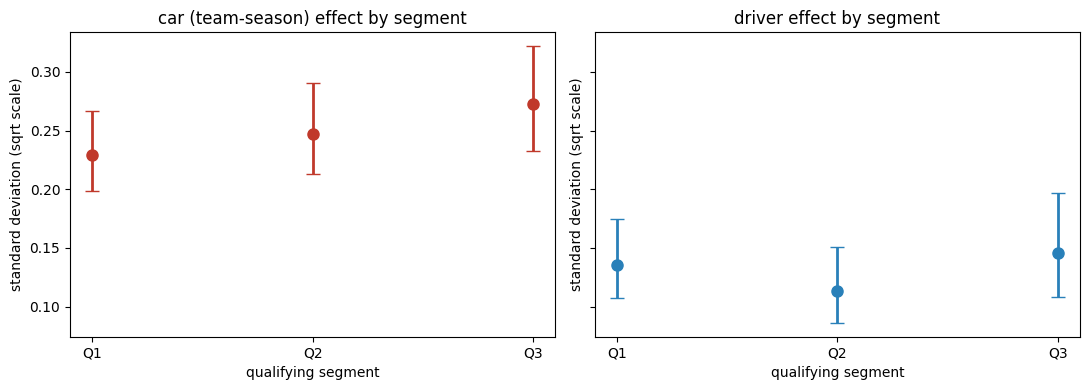

In [17]:
# one shared axis: the whole point is how these two magnitudes compare
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
positions = range(len(fits))

for ax, (label, prefix, colour) in zip(axes, [('car (team-season)', 'car', '#c0392b'),
                                              ('driver', 'driver', '#2980b9')]):
    ax.errorbar(positions, intervals[f'{prefix}_med'],
                yerr=[intervals[f'{prefix}_med'] - intervals[f'{prefix}_lo'],
                      intervals[f'{prefix}_hi'] - intervals[f'{prefix}_med']],
                fmt='o', capsize=5, color=colour, lw=2, ms=8)
    ax.set_xticks(positions)
    ax.set_xticklabels(intervals.index)
    ax.set_title(f'{label} effect by segment')
    ax.set_ylabel('standard deviation (sqrt scale)')
    ax.set_xlabel('qualifying segment')

plt.tight_layout()
plt.show()

In [18]:
# The three segment fits above use different sessions, different drivers and different
# teams, so composition and segment change together. Here only the segment changes:
# the same driver-sessions, measured once in Q1 and once in Q3.
key = ['season', 'gp', 'drv']
q1_rows = segments['Q1'][segments['Q1']['within_107']]
q3_rows = segments['Q3'][segments['Q3']['within_107']]

matched_q1 = q1_rows.merge(q3_rows[key], on=key)
matched_q3 = q3_rows.merge(q1_rows[key], on=key)

print(f'driver-sessions run in both segments: {len(matched_q1)}')
print(f'  sessions {matched_q1.groupby(["season", "gp"]).ngroups}  '
      f'drivers {matched_q1["drv"].nunique()}  '
      f'team-seasons {matched_q1["team_season"].nunique()}')
print()

matched = {'Q1 matched': fit_variant(matched_q1, 'Q1 matched'),
           'Q3 matched': fit_variant(matched_q3, 'Q3 matched')}

print()
print(pd.DataFrame({name: effect_sizes(fitted)
                    for name, fitted in matched.items()}).T.round(3).to_string())

car_q1 = matched['Q1 matched'].posterior['1|team_season_sigma'].values.flatten()
car_q3 = matched['Q3 matched'].posterior['1|team_season_sigma'].values.flatten()
drv_q1 = matched['Q1 matched'].posterior['1|drv_sigma'].values.flatten()
drv_q3 = matched['Q3 matched'].posterior['1|drv_sigma'].values.flatten()

print()
print(f'P(car spread larger in Q3) = {np.mean(car_q3 > car_q1):.3f}')
print(f'P(ratio larger in Q3)      = {np.mean((car_q3 / drv_q3) > (car_q1 / drv_q1)):.3f}')

# which sessions have Q3 laps but no usable Q1 laps, the reason the segment counts rise
only_q3 = (set(map(tuple, q3_rows[['season', 'gp']].drop_duplicates().to_numpy()))
           - set(map(tuple, q1_rows[['season', 'gp']].drop_duplicates().to_numpy())))
print()
print('sessions with Q3 laps but no usable Q1 laps:', sorted(only_q3))

driver-sessions run in both segments: 1481
  sessions 154  drivers 33  team-seasons 77



Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 65 seconds.


Q1 matched               rows= 1481  divergences=  0  max R-hat=1.0047


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 92 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


Q3 matched               rows= 1481  divergences=  0  max R-hat=1.0104

            driver_sd  car_sd  residual_sd  car_over_driver  ratio_lower  ratio_upper
Q1 matched      0.112   0.162        0.299            1.436        1.013        2.080
Q3 matched      0.145   0.271        0.309            1.862        1.303        2.658

P(car spread larger in Q3) = 1.000
P(ratio larger in Q3)      = 0.815

sessions with Q3 laps but no usable Q1 laps: [(2018, 'Australian Grand Prix'), (2018, 'Canadian Grand Prix'), (2018, 'French Grand Prix')]


### The prediction holds, and the segments are not comparable

| segment | driver effect | car effect | car ÷ driver |
|---|---|---|---|
| Q1 | 0.136 [0.107, 0.175] | 0.229 [0.198, 0.267] | 1.687 |
| Q2 | 0.114 [0.086, 0.151] | 0.247 [0.213, 0.291] | 2.175 |
| Q3 | 0.146 [0.108, 0.197] | **0.273** [0.233, 0.322] | 1.868 |

**How to read this.** Each figure is how far apart drivers, or cars, typically are on the model's scale. The brackets give the plausible range.

**The gap between cars widens from Q1 to Q3, as predicted.** But this comparison changes far more than the segment, in three ways that all cut the same direction.

**The fields differ.** Q3 has 34 drivers against 43, 77 team-seasons against 81, and ten cars per session rather than twenty, from however many teams got one through. These six counts are unfiltered; the fits above use the 107%-filtered rows, whose field is not printed anywhere. Truncation should shrink a spread, which cuts against the car result and so strengthens it. But it applies to the driver term equally, which is easy to forget.

**The sessions differ.** Q1 covers 156, Q2 158, Q3 159. Q3 cannot be a superset of qualifying. The cause is three 2018 rounds with usable Q3 laps and no usable Q1 laps: **Australia, Canada and France**. Q2's extra two are not accounted for. A whole segment can go missing, so the segment labelling itself is not fully trustworthy, and every fit here depends on it.

**The driver series is not flat**, running 0.136, 0.114, 0.146, and the ratio peaks at Q2 rather than Q3, which steadily increasing effort does not predict. The Q2 tyre rule is the likeliest reason. The three-segment comparison cannot carry the weight put on it, so read the matched version below instead.

### The same test with the field held constant

Take every driver-session with a valid lap in both Q1 and Q3, and fit the model twice on that one set.

| matched fit, 1,481 driver-sessions | driver | car | residual | car ÷ driver |
|---|---|---|---|---|
| Q1 | 0.112 | 0.162 | 0.299 | 1.436 [1.013, 2.080] |
| Q3 | 0.145 | **0.271** | 0.309 | 1.862 [1.303, 2.658] |

Same 154 sessions, same 33 drivers, same 77 team-seasons. Only the lap changes.

**The car spread grows by two thirds, and the posterior probability it is larger in Q3 is 1.000**, which means no draw out of 6,000 went the other way. Read that as "above 0.9998" rather than as a certainty.

**The ratio also rises, 1.436 to 1.862, but with probability 0.815.** Keep the two apart: that cars are further apart in Q3 is about as settled as this data gets, while their being further apart *relative to drivers* is likely rather than established.

**One diagnostic caveat.** The Q3 matched fit reports a worst R-hat of 1.0104, just over the 1.01 this project treats as the pass mark, with no divergences. It would want more draws before being leaned on harder.

**A scale check, which turns out to be the wrong one.** The model works on the square root of the gap, which is not scale-free: if the typical gap were smaller in one segment, its spread would inflate for arithmetic reasons. The full-table mean gaps are 1.090%, 0.950% and 0.962%, near enough identical. **That check is superseded in the next section**: it was computed on all rows rather than the matched ones, where the picture is different.

**The residual moves little, 0.299 to 0.309, while the car term grows 67%.** That rules out everything inflating together, but not a shift that lands on some components and not others, which is what the next section examines.

In [19]:
# Four ways this result could be wrong, tested rather than argued.

# 1. The scale check in the cell above was computed on the FULL segment tables. The
#    matched fit runs on Q3-qualified rows only, where the typical Q1 gap is smaller.
print('mean gap on the rows the matched fits actually use:')
print(f'  matched Q1 {matched_q1["gap_to_fastest"].mean():.3f}%   '
      f'matched Q3 {matched_q3["gap_to_fastest"].mean():.3f}%')

# 2. sqrt() is not scale-free, so a level shift alone inflates every component. On a log
#    scale a multiplicative shift lands entirely in the intercept and cannot do that.
LOG_PRIORS = {
    'Intercept': bmb.Prior('Normal', mu=0, sigma=2),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=1)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=1)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=1)),
    'sigma': bmb.Prior('HalfNormal', sigma=2),
}
logged = {}
for name, frame in [('Q1 log', matched_q1), ('Q3 log', matched_q3)]:
    positive = frame[frame['gap_to_fastest'] > 0].copy()
    positive['log_gap'] = np.log(positive['gap_to_fastest'])
    model = bmb.Model('log_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)',
                      data=positive, priors=LOG_PRIORS)
    logged[name] = model.fit(**FIT_ARGS)

print()
print(pd.DataFrame({n: effect_sizes(f) for n, f in logged.items()}).T.round(3).to_string())
car_lo_q1 = logged['Q1 log'].posterior['1|team_season_sigma'].values.flatten()
car_lo_q3 = logged['Q3 log'].posterior['1|team_season_sigma'].values.flatten()
drv_lo_q1 = logged['Q1 log'].posterior['1|drv_sigma'].values.flatten()
drv_lo_q3 = logged['Q3 log'].posterior['1|drv_sigma'].values.flatten()
print(f'  on the log scale: P(car larger in Q3) = {np.mean(car_lo_q3 > car_lo_q1):.3f}, '
      f'P(driver larger) = {np.mean(drv_lo_q3 > drv_lo_q1):.3f}, '
      f'P(ratio larger) = {np.mean((car_lo_q3 / drv_lo_q3) > (car_lo_q1 / drv_lo_q1)):.3f}')

# the driver half of the registered prediction, on the original scale
print(f'  on the sqrt scale: P(driver larger in Q3) = '
      f'{np.mean(matched["Q3 matched"].posterior["1|drv_sigma"].values.flatten() > matched["Q1 matched"].posterior["1|drv_sigma"].values.flatten()):.3f}')

# 3. The car prior is wider than the driver prior, so the priors alone imply a ratio.
#    Rescaling both proportionally would preserve it; only setting them equal tests it.
equal = dict(PRIORS)
for term in ('1|drv', '1|team_season'):
    equal[term] = bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.4))
baseline_rows = segments['Q1'][segments['Q1']['within_107']]
print()
print('prior sensitivity, baseline Q1:')
print(pd.DataFrame({
    'as fitted (0.3 / 0.5)': effect_sizes(fits['Q1']),
    'equal hyperpriors (0.4 / 0.4)': effect_sizes(
        bmb.Model(FORMULA, data=baseline_rows, priors=equal).fit(**FIT_ARGS)),
}).T.round(3).to_string())

# 4. The driver term is one number per career while the car term refits every season.
#    Making them symmetric is the largest researcher choice available here.
symmetric = {k: v for k, v in PRIORS.items() if k != '1|drv'}
symmetric['1|drv_season'] = bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5))
per_season = baseline_rows.assign(drv_season=baseline_rows['drv'] + ' ' + baseline_rows['season'].astype(str))
sym_fit = bmb.Model('sqrt_gap ~ 1 + (1|drv_season) + (1|team_season) + (1|season)',
                    data=per_season, priors=symmetric).fit(**FIT_ARGS)
sym_driver = sym_fit.posterior['1|drv_season_sigma'].values.flatten()
sym_car = sym_fit.posterior['1|team_season_sigma'].values.flatten()
print()
print(f'driver measured per season instead of per career: driver {np.median(sym_driver):.3f}  '
      f'car {np.median(sym_car):.3f}  ratio {np.median(sym_car / sym_driver):.3f} '
      f'[{np.percentile(sym_car / sym_driver, 5.5):.3f}, {np.percentile(sym_car / sym_driver, 94.5):.3f}]')

# 5. Sandbagging predicts the strong teams gain most between segments. A general
#    conditions effect (grip, tyres, engine modes) predicts a roughly uniform gain.
gains = matched_q1.merge(matched_q3[['season', 'gp', 'drv', 'best_lap']],
                         on=['season', 'gp', 'drv'], suffixes=('_q1', '_q3'))
gains['improvement'] = (gains['best_lap_q1'] - gains['best_lap_q3']) / gains['best_lap_q1'] * 100
strength = baseline_rows.groupby('team_season')['gap_to_fastest'].mean().rank(pct=True)
gains['quartile'] = pd.cut(gains['team_season'].map(strength), [0, .25, .5, .75, 1.0],
                           labels=['fastest 25%', '2nd', '3rd', 'slowest 25%'])
print()
print('how much a driver improves their own lap from Q1 to Q3 (%), by team strength:')
print(gains.groupby('quartile', observed=True)['improvement']
      .agg(['mean', 'median', 'size']).round(3).to_string())

# and the run counts behind the mechanism, within Q1 rather than across segments
runs = baseline_rows.assign(quartile=pd.cut(baseline_rows['team_season'].map(strength),
                                            [0, .25, .5, .75, 1.0],
                                            labels=['fastest 25%', '2nd', '3rd', 'slowest 25%']))
print()
print('timed laps per driver-session within Q1, by team strength:')
print(runs.groupby('quartile', observed=True)['n_valid_laps'].agg(['mean', 'size']).round(2).to_string())

mean gap on the rows the matched fits actually use:
  matched Q1 0.678%   matched Q3 0.945%


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 42 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

...

                               driver_sd  car_sd  residual_sd  car_over_driver  ratio_lower  ratio_upper
as fitted (0.3 / 0.5)              0.136   0.229        0.296            1.687        1.245        2.285
equal hyperpriors (0.4 / 0.4)      0.135   0.229        0.296            1.691        1.251        2.278


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_season_sigma, 1|drv_season_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 142 seconds.



driver measured per season instead of per career: driver 0.117  car 0.269  ratio 2.307 [1.818, 2.915]

how much a driver improves their own lap from Q1 to Q3 (%), by team strength:
              mean  median  size
quartile                        
fastest 25%  0.868   1.052   666
2nd          0.997   0.764   458
3rd          0.336   0.641   240
slowest 25%  0.091   0.611   117

timed laps per driver-session within Q1, by team strength:
             mean  size
quartile               
fastest 25%  3.31   757
2nd          3.52   824
3rd          3.56   681
slowest 25%  3.72   746


### Four ways this could still be wrong

The matched design fixes composition, not everything. Four objections survive it, each tested above rather than argued.

**1. The scale check was run on the wrong rows, and redoing it matters.** The mean gaps quoted earlier come from the full segment tables. The matched fits use Q3-qualified rows only, where the typical Q1 gap is **0.678%** against Q3's **0.945%**. The square root is not scale-free, so a level shift that size inflates every standard deviation by about 1.18 times on its own, and every variance by about 1.39. My earlier check did not test the fit it was defending.

**2. So the same pair is refitted on a log scale.** There a multiplicative level shift lands entirely in the intercept and cannot touch a variance component. The car spread rises **0.317 to 0.563**, a 78% increase, with P(larger in Q3) = **1.000**. The residual falls slightly. The effect is larger on this scale, not smaller.

**Two caveats, because that refit is not as clean as it looks.** `log` is undefined at zero, so the fit silently drops each session's fastest lap. That is a different row in Q1 than in Q3, so it breaks the matching this section exists to preserve. It does not even drop the same *number*: 147 rows from one arm, 151 from the other. Second, it uses wider priors than the main fits, so its ratio is not directly comparable to theirs. Read it as evidence that the widening is not an artefact of the square root, which is what it was run for. Do not read it as a second estimate of the effect.

The same table holds one more result. On the log scale the Q1 ratio's interval runs [0.936, 2.163]. So on these top-ten rows measured in Q1 alone, the car outweighing the driver is not established at all. It is established in Q3, [1.435, 3.047]. That is the point.

**3. The driver half of the prediction is not confirmed.** The registration said driver spread should stay where it is. It rises 29% on the sqrt scale, where P(driver larger in Q3) is **0.859**, and 21% on the log scale, where it is **0.777**. That is neither "stays put" nor a clean failure. It is unresolved, and about the size the level shift alone would produce. The car result does not depend on it, but a pre-registered prediction with two halves should report both.

**4. The priors are not doing the work, and the specification is.** The car hyperprior is wider than the driver's, which alone implies a ratio of 1.67 against a reported 1.69. Setting both to 0.4 moves the answer to **1.691** against 1.687, so the likelihood decides it. But the driver term is one number per career while the car term refits every season. Making them symmetric moves the ratio to **2.307** [1.818, 2.915]. That is the largest single lever in this notebook, and it moves the answer **up**: the headline is conservative with respect to it.

### Sandbagging, or just a faster track?

Q3 has fresh soft tyres and a rubbered-in surface, and until qualifying engine modes were banned in September 2020 it had those too. All of that widens the gap between a good car and a bad one without anybody holding back, and predicts the same sign as sandbagging in every test so far.

The two differ in one way. **A general conditions effect should lift everyone by roughly the same amount. Sandbagging should lift the strong teams most, because only they had something in hand.**

Each driver's improvement on their own lap time from Q1 to Q3, by how strong their car was:

| team strength | median | mean | rows |
|---|---|---|---|
| **fastest 25%** | **1.05%** | 0.87% | 666 |
| second quarter | 0.76% | 1.00% | 458 |
| third quarter | 0.64% | 0.34% | 240 |
| slowest 25% | 0.61% | 0.09% | 117 |

**The medians are monotone; the means are not**, because the second quarter carries a few very large gains. Both columns are shown because picking the one that runs the right way would be the sort of choice this notebook exists to test. The medians say the fastest quarter finds about 1.7 times what the slowest does.

**And there is a selection problem in the bottom row.** A slow car reaches Q3 only on its best weekends, which is why that quartile has 117 rows against the fastest quartile's 666. Those are the sessions where it was already near its ceiling in Q1, so it had least left to find. Some of the gradient is that, not withholding. And within Q1 it is the *fastest* quarter that takes the fewest timed laps, 3.31 against the slowest quarter's 3.72. Both point at withholding rather than at grip alone. Conditions and sandbagging are not fully separable here, and some of the widening is likely to be the track.

In [20]:
q1 = segments['Q1']

variants = {
    'baseline (Q1, 107%)': q1[q1['within_107']],
    'dry sessions only': q1[q1['within_107'] & q1['rain_fraction'].eq(0)],
    'no 107% filter': q1,
    'drivers with 20+ sessions': q1[q1['within_107'] & q1.groupby('drv')['drv']
                                    .transform('size').ge(20)],
}

variant_fits = {'baseline (Q1, 107%)': fits['Q1']}
for label, table in variants.items():
    if label not in variant_fits:
        variant_fits[label] = fit_variant(table, label)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 133 seconds.


dry sessions only        rows= 2493  divergences=  0  max R-hat=1.0033


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


...

no 107% filter           rows= 3029  divergences=  0  max R-hat=1.0063


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 126 seconds.


drivers with 20+ sessions rows= 2892  divergences=  0  max R-hat=1.0053


In [21]:
def driver_effects(fitted):
    posterior = fitted.posterior
    draws = posterior['1|drv'].values.reshape(-1, posterior['1|drv'].shape[-1])
    names = posterior['1|drv'].coords['drv__factor_dim'].values
    return pd.Series(np.median(draws, axis=0), index=names)


baseline_effects = driver_effects(variant_fits['baseline (Q1, 107%)'])

rows = []
for label, fitted in variant_fits.items():
    effects = driver_effects(fitted)
    shared = baseline_effects.index.intersection(effects.index)
    rho = spearmanr(baseline_effects[shared], effects[shared]).statistic
    sizes = effect_sizes(fitted)
    rows.append({
        'variant': label,
        'drivers': len(effects),
        'rank_corr_vs_baseline': rho,
        'driver_sd': sizes['driver_sd'],
        'car_sd': sizes['car_sd'],
        'car_over_driver': sizes['car_over_driver'],
    })

pd.DataFrame(rows).set_index('variant').round(3)

,drivers,rank_corr_vs_baseline,driver_sd,car_sd,car_over_driver
variant,,,,,
"baseline (Q1, 107%)",43,1.000,0.136,0.229,1.687
dry sessions only,43,0.968,0.125,0.229,1.832
no 107% filter,43,0.971,0.161,0.220,1.368
drivers with 20+ sessions,33,0.996,0.143,0.227,1.587


### The ranking holds; the exact ratio doesn't

| variant | rank corr | driver sd | car sd | car ÷ driver |
|---|---|---|---|---|
| baseline (Q1, 107%) | 1.000 | 0.136 | 0.229 | 1.69 |
| dry sessions only | 0.968 | 0.125 | 0.229 | 1.83 |
| no 107% filter | 0.971 | **0.161** | 0.220 | 1.37 |
| drivers with 20+ sessions | 0.996 | 0.143 | 0.227 | 1.59 |

**How to read this.** `rank corr` compares the driver order against the baseline fit's: 1.000 is the identical order, 0 would mean no relationship at all. `driver sd` and `car sd` are the same spread measures as above, and the last column is one divided by the other.

**Who is fast stays fast.** Agreement with the baseline order never falls below 0.968: not when every wet session is deleted, not when the 107% filter comes off, not when ten drivers are removed from the data outright.

**The car figure barely moves**, holding between 0.220 and 0.229 across all four fits. Whatever these decisions change, it is not the estimate of how much the machinery is worth.

**The 107% rule is the one choice that carries weight.** Take it away and the driver spread jumps 18%, from 0.136 to 0.161, while the car figure stays put. A lap 45% off the pace is not information about how quick a driver is, it is a session that went wrong. With no filter, the model reads it as evidence about the driver's speed. The car estimate escapes because ruined laps happen to Williams and Mercedes alike, scattered across the grid rather than piling up in one garage.

That is a late vindication of a decision taken in notebook 01 purely on F1 grounds: borrow the sport's own qualifying threshold instead of inventing a cutoff.

**The drivers with thin records turn out not to matter.** Removing the ten who appear least changes the order of everyone who remains by almost nothing (0.996 agreement). The model was already pulling ratings built on a handful of sessions toward the average, which is what it was set up to do.

## What this means for the headline number

**The number this project is built around is "the car counts for about 2.8 times the driver."** That 2.8 is a ratio of variances; the tables here are standard deviations, where the same result reads as 1.69.

Three sources of movement, and they are not the same size:

| source | range, squared |
|---|---|
| the four Q1 variants | 1.9x to 3.4x |
| a single fit's own 89% interval | 1.55x to 5.22x |
| measuring the driver per season | 5.32x, interval to 8.5x |

Posterior uncertainty and specification uncertainty are different quantities and do not nest, so they add. **The defensible band is roughly 1.5 to 8 times**, with 2.8 sitting low inside it. The direction never reverses under any choice tested.

**On the floor claim.** Every maximum-effort comparison puts the car further ahead than Q1 does, and so does the symmetric specification, so 2.8 is likelier to understate than overstate. But it is not a floor in the strict sense: removing the 107% filter, a defensible choice, gives 1.87x. What can be defended is that **Q1 measures the car conservatively**, not that no choice can push the number below 2.8.

**And one number that belongs next to all of these.** The model explains under half of what happens in qualifying: the residual is the largest single component in every fit here. "The car is 67%" means 67% of the part the model accounts for, not 67% of qualifying.

## Quantified takeaways

1. **The car half of the pre-registered prediction passes, and survives its own strongest objection.** On 1,481 driver-sessions run in both segments the car spread rises 0.162 to 0.271 with probability 1.000. Refitting on a log scale, where a level shift cannot inflate a variance component, makes the effect larger rather than smaller: 0.317 to 0.563, +78%.

2. **The driver half is unresolved, not confirmed.** The prediction said driver spread would stay put. It rises 21% to 29% depending on scale, with P(larger in Q3) between 0.777 and 0.859, about what the level shift alone would produce. Reporting one half of a two-part registration as a pass would defeat the point of registering it.

3. **The widening looks like withholding rather than only grip.** A general conditions effect predicts a uniform gain. Instead the strongest quarter of the field improves its own lap by 1.05% between segments against 0.61% for the slowest, and takes the fewest timed laps in Q1 while doing it. The two are not fully separable and some of the effect is the track.

4. **Who is fast barely depends on any of these choices.** Agreement with the baseline driver order never falls below 0.968 across dry-only, no-107%-filter and 20-plus-sessions variants, and the car spread stays between 0.220 and 0.229.

5. **The choices that move the answer are the 107% filter and the specification.** Removing the filter inflates driver spread 18% on 21 rows out of 3,029, dropping the ratio to 1.37. Measuring the driver per season rather than per career raises it to 2.31. Priors do not matter: equal hyperpriors give 1.691 against 1.687.

6. **Two uncertainties, and they add rather than nest.** The baseline fit's own 89% interval squares to [1.55, 5.22] and contains every Q1 variant, but not the per-season specification at 5.32. Combining them gives roughly one and a half to eight times, direction never in doubt, with 2.8 sitting low in that band and so on the conservative side.